# 6) Structural Descriptors vs. Isolated Thermodynamics

This notebook joins the structural descriptors collected with `cosymlib` to the isolated thermodynamic data and searches for simple Pearson correlations. The analysis now includes the convex-hull molecular volume descriptors (`HS_CH_volume`, `LS_CH_volume`) and considers several thermodynamic quantities: electronic, vibrational, entropic, total free-energy, and transition-temperature estimates.

`TEPVIW` is absent from the structural file and is therefore naturally excluded by the inner join on `id`.


In [1]:
import sys

scope_repo = "/Users/sergivela/Documents/SCOPE/Program/Scope"
sys.path.insert(0, f"{scope_repo}/core/src")
sys.path.insert(0, f"{scope_repo}/sco/src")

import scope
import scope_sco

In [2]:
import csv
import math
import sys
from pathlib import Path

scope_repo = Path('/Users/sergivela/Documents/SCOPE/Program/Scope')
sys.path[:0] = [str(scope_repo / 'core/src'), str(scope_repo / 'sco/src')]

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial import ConvexHull, QhullError

def first_float(value):
    if value in (None, '', 'None', 'nan', 'NaN', 'error'):
        return None
    if isinstance(value, (int, float)):
        return float(value)
    text = str(value).strip().strip('[]')
    if not text:
        return None
    try:
        return float(text.replace(',', ' ').split()[0])
    except (IndexError, ValueError):
        return None


def safe_diff(a, b):
    return a - b if a is not None and b is not None else None


def safe_abs(value):
    return abs(value) if value is not None else None


def safe_ratio(a, b):
    return a / b if a is not None and b not in (None, 0) else None


def base_refcode(refcode):
    # Match six-letter CSD identifiers while retaining suffixed paths elsewhere.
    text = str(refcode)
    return text[:6] if len(text) >= 6 and text[:6].isalpha() else text


def get_CH_volume(coord):
    coords = np.asarray(coord, dtype=float)
    if coords.shape[0] < 4:
        return np.nan
    try:
        return float(ConvexHull(coords).volume)
    except QhullError:
        return np.nan


In [3]:
%run ./5a-Core_Ring_Map_Functions.ipynb

In [4]:
project_path = Path('/Users/sergivela/Documents/SCOPE/Database_SCO')
root_path = project_path / 'Analysis/1-Analyse_Database'
outputs_path = root_path / 'Outputs'
figures_path = Path('/Users/sergivela/Documents/SCOPE/Database_SCO/Figures')

structural_path = outputs_path / 'unique_structural_data.csv'
thermo_path = outputs_path / 'unique_thermodynamic_data.csv'

## Load And Merge

In [5]:
structural_rows = read_csv(structural_path)
thermo_rows     = read_csv(thermo_path)

structural_by_id = {base_refcode(row['refcode']): row for row in structural_rows}

rows = []
for thermo in thermo_rows:
    refcode = base_refcode(thermo['refcode'])
    struct = structural_by_id.get(refcode)
    if struct is None:
        continue

    row = {
        'id': refcode,
        'dHelec': first_float(thermo['dHelec[kJ/mol]']),
        'dHvib': first_float(thermo['dHvib[kJ/mol](T=298K)']),
        'TdSvib': first_float(thermo['dSvib·T[kJ/mol](T=298K)']),
        'dGtot': first_float(thermo['dGtot[kJ/mol](T=298K)']),
        'T12': first_float(thermo['T12[K]']),
        'homoleptic': thermo['homoleptic'] == 'True',
        'denticity': thermo['denticity'],
        'HS_FeN': first_float(struct['HS_dFeN']),
        'LS_FeN': first_float(struct['LS_dFeN']),
        'HS_Epsylon': first_float(struct['HS_Sigma']),
        'LS_Epsylon': first_float(struct['LS_Sigma']),
        'HS_CShM': first_float(struct['HS_CShM']),
        'LS_CShM': first_float(struct['LS_CShM']),
        'HS_CH': first_float(struct['HS_CH_volume']),
        'LS_CH': first_float(struct['LS_CH_volume']),
        'HS_FCS_CH': first_float(struct['HS_FCS_CH_volume']),
        'LS_FCS_CH': first_float(struct['LS_FCS_CH_volume']),
    }
    row['dFeN']         = safe_diff(row['HS_FeN'], row['LS_FeN'])
    row['abs_dFeN']     = safe_abs(row['dFeN'])
    row['dEpsylon']     = safe_diff(row['HS_Epsylon'], row['LS_Epsylon'])
    row['abs_dEpsylon'] = safe_abs(row['dEpsylon'])
    row['dCShM']        = safe_diff(row['HS_CShM'], row['LS_CShM'])
    row['abs_dCShM']    = safe_abs(row['dCShM'])
    row['dCH']          = safe_diff(row['HS_CH'], row['LS_CH'])
    row['abs_dCH']      = safe_abs(row['dCH'])
    row['rel_dCH']      = safe_ratio(row['dCH'], row['LS_CH'])
    row['dFCS_CH']       = safe_diff(row['HS_FCS_CH'], row['LS_FCS_CH'])
    row['abs_dFCS_CH']   = safe_abs(row['dFCS_CH'])
    row['rel_dFCS_CH']   = safe_ratio(row['dFCS_CH'], row['LS_FCS_CH'])
    rows.append(row)

unfiltered_rows = rows
negative_dFeN_rows = [row for row in unfiltered_rows if row['dFeN'] is not None and row['dFeN'] < 0]
rows = [row for row in unfiltered_rows if row['dFeN'] is None or row['dFeN'] >= 0]
invalid_fcs_rows = [row for row in rows if row['dFCS_CH'] is None]
negative_dFCS_rows = [row for row in rows if row['dFCS_CH'] is not None and row['dFCS_CH'] < 0]

excluded_systems_path = outputs_path / 'structure_thermo_excluded_systems.csv'
with open(excluded_systems_path, 'w', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=[
        'id', 'HS_FeN[Angstrom]', 'LS_FeN[Angstrom]', 'dFeN_HS-LS[Angstrom]', 'reason'
    ])
    writer.writeheader()
    writer.writerows({
        'id': row['id'],
        'HS_FeN[Angstrom]': row['HS_FeN'],
        'LS_FeN[Angstrom]': row['LS_FeN'],
        'dFeN_HS-LS[Angstrom]': round(row['dFeN'], 4),
        'reason': 'Negative LS-to-HS Fe-N distance change',
    } for row in negative_dFeN_rows)

print(f'Structural rows: {len(structural_rows)}')
print(f'Thermodynamic rows: {len(thermo_rows)}')
print(f'Merged rows before filtering: {len(unfiltered_rows)}')
print(f'Excluded negative dFeN systems: {len(negative_dFeN_rows)}')
print('Excluded ids:', [row['id'] for row in negative_dFeN_rows])
print(f'Rows retained for correlations: {len(rows)}')
print(f'Rows with valid paired FCS hulls: {len(rows) - len(invalid_fcs_rows)}')
print('Rows excluded from paired FCS analysis:', [row['id'] for row in invalid_fcs_rows])
print('Negative FCS hull changes after dFeN filtering:', [row['id'] for row in negative_dFCS_rows])
print('Missing structural ids:', sorted(set(base_refcode(row['refcode']) for row in thermo_rows) - set(structural_by_id)))


Structural rows: 604
Thermodynamic rows: 604
Merged rows before filtering: 604
Excluded negative dFeN systems: 0
Excluded ids: []
Rows retained for correlations: 604
Rows with valid paired FCS hulls: 604
Rows excluded from paired FCS analysis: []
Negative FCS hull changes after dFeN filtering: []
Missing structural ids: []


## Correlation Helpers

In [6]:
targets = ['dHelec', 'dHvib', 'TdSvib', 'dGtot', 'T12']
target_labels = {
    'dHelec': r'$\Delta H_{\mathrm{elec}}$ [kJ/mol]',
    'dHvib': r'$\Delta H_{\mathrm{vib}}$ [kJ/mol]',
    'TdSvib': r'$T\Delta S_{\mathrm{vib}}$ [kJ/mol]',
    'dGtot': r'$\Delta G_{\mathrm{tot}}$ [kJ/mol]',
    'T12': r'$T_{1/2}$ [K]',
}

features = [
    'HS_FeN', 'LS_FeN', 'dFeN', 'abs_dFeN',
    'HS_Epsylon', 'LS_Epsylon', 'dEpsylon', 'abs_dEpsylon',
    'HS_CShM', 'LS_CShM', 'dCShM', 'abs_dCShM',
    'HS_CH', 'LS_CH', 'dCH', 'abs_dCH', 'rel_dCH',
    'HS_FCS_CH', 'LS_FCS_CH', 'dFCS_CH', 'abs_dFCS_CH', 'rel_dFCS_CH',
]

feature_labels = {
    'HS_CH': r'HS convex-hull volume [$\AA^3$]',
    'LS_CH': r'LS convex-hull volume [$\AA^3$]',
    'dCH': r'$\Delta V_{\mathrm{hull}}$ [$\AA^3$]',
    'abs_dCH': r'$|\Delta V_{\mathrm{hull}}|$ [$\AA^3$]',
    'rel_dCH': r'$\Delta V_{\mathrm{hull}} / V_{\mathrm{LS}}$',
    'HS_FCS_CH': r'HS first-sphere hull volume [$\AA^3$]',
    'LS_FCS_CH': r'LS first-sphere hull volume [$\AA^3$]',
    'dFCS_CH': r'$\Delta V_{\mathrm{FCS}}$ [$\AA^3$]',
    'abs_dFCS_CH': r'$|\Delta V_{\mathrm{FCS}}|$ [$\AA^3$]',
    'rel_dFCS_CH': r'$\Delta V_{\mathrm{FCS}} / V_{\mathrm{FCS}}^{\mathrm{LS}}$',
}

def sorted_denticities(rows):
    return sorted(d for d in set(row['denticity'] for row in rows) if d != 'unknown')

def finite_pairs(subset, feature, target):
    return [
        (row[feature], row[target])
        for row in subset
        if row[feature] is not None and row[target] is not None
        and math.isfinite(row[feature]) and math.isfinite(row[target])
    ]

def pearson_correlation(subset, feature, target='dHelec'):
    pairs = finite_pairs(subset, feature, target)
    if len(pairs) < 3:
        return None, len(pairs)

    x = np.array([pair[0] for pair in pairs])
    y = np.array([pair[1] for pair in pairs])
    if np.std(x) == 0 or np.std(y) == 0:
        return None, len(pairs)
    return float(np.corrcoef(x, y)[0, 1]), len(pairs)

def correlation_table(subset, label, target='dHelec', feature_list=None):
    table = []
    for feature in feature_list or features:
        r, n = pearson_correlation(subset, feature, target=target)
        if r is not None:
            table.append({'group': label, 'target': target, 'feature': feature, 'r': r, 'abs_r': abs(r), 'n': n})
    return sorted(table, key=lambda row: row['abs_r'], reverse=True)

def print_table(table, limit=None):
    print(f"{'target':<8} {'group':<14} {'feature':<14} {'r':>8} {'n':>5}")
    print('-' * 57)
    for row in table[:limit]:
        print(f"{row['target']:<8} {row['group']:<14} {row['feature']:<14} {row['r']:>8.3f} {row['n']:>5}")


## Overall, Homoleptic, And Heteroleptic Trends

In [7]:
group_subsets = [
    ('overall', rows),
    ('homoleptic', [row for row in rows if row['homoleptic']]),
    ('heteroleptic', [row for row in rows if not row['homoleptic']]),
]

summary_tables = []
for target in targets:
    for label, subset in group_subsets:
        summary_tables.extend(correlation_table(subset, label, target=target)[:6])

print_table(summary_tables)


target   group          feature               r     n
---------------------------------------------------------
dHelec   overall        HS_FeN           -0.617   604
dHelec   overall        LS_FeN           -0.434   604
dHelec   overall        LS_FCS_CH        -0.373   604
dHelec   overall        HS_FCS_CH        -0.346   604
dHelec   overall        rel_dCH           0.343   604
dHelec   overall        HS_CH             0.297   604
dHelec   homoleptic     HS_FeN           -0.696   301
dHelec   homoleptic     LS_FeN           -0.629   301
dHelec   homoleptic     LS_FCS_CH        -0.526   301
dHelec   homoleptic     rel_dFCS_CH       0.382   301
dHelec   homoleptic     HS_FCS_CH        -0.303   301
dHelec   homoleptic     dFeN              0.287   301
dHelec   heteroleptic   HS_FeN           -0.703   303
dHelec   heteroleptic   HS_Epsylon       -0.433   303
dHelec   heteroleptic   HS_FCS_CH        -0.420   303
dHelec   heteroleptic   LS_Epsylon       -0.401   303
dHelec   heteroleptic   

## Trends By Denticity

In [8]:
by_denticity = []
for target in targets:
    for denticity in sorted_denticities(rows):
        subset = [row for row in rows if row['denticity'] == denticity]
        by_denticity.extend(correlation_table(subset, f'dent={denticity}', target=target)[:5])

print_table(by_denticity)


target   group          feature               r     n
---------------------------------------------------------
dHelec   dent=1         dEpsylon         -0.858    12
dHelec   dent=1         abs_dEpsylon      0.841    12
dHelec   dent=1         dCShM            -0.819    12
dHelec   dent=1         HS_FCS_CH        -0.795    12
dHelec   dent=1         HS_FeN           -0.788    12
dHelec   dent=2         HS_FeN           -0.839    50
dHelec   dent=2         LS_FCS_CH        -0.777    50
dHelec   dent=2         HS_FCS_CH        -0.769    50
dHelec   dent=2         LS_FeN           -0.753    50
dHelec   dent=2         abs_dCH           0.369    50
dHelec   dent=3         HS_FeN           -0.697   208
dHelec   dent=3         LS_FeN           -0.571   208
dHelec   dent=3         LS_FCS_CH        -0.499   208
dHelec   dent=3         rel_dFCS_CH       0.347   208
dHelec   dent=3         HS_FCS_CH        -0.330   208
dHelec   dent=6         LS_FeN           -0.843    31
dHelec   dent=6         

## Main Scatter Plots

These plots show the strongest and most interpretable descriptor: the average Fe-N distance in the HS state. The same function can be reused for any descriptor in `features`.

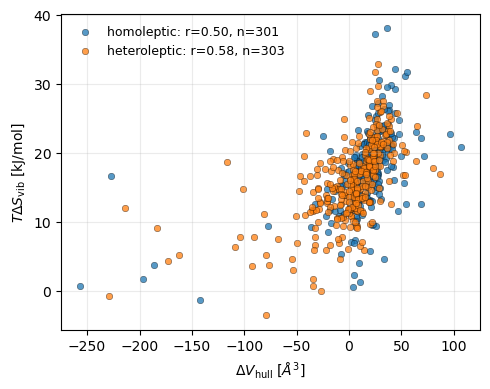

In [9]:
def scatter_by_group(feature, target='dHelec'):
    fig, ax = plt.subplots(figsize=(5, 4), tight_layout=True)
    groups = [
        ('homoleptic', [row for row in rows if row['homoleptic']], 'tab:blue'),
        ('heteroleptic', [row for row in rows if not row['homoleptic']], 'tab:orange'),
    ]

    for label, subset, color in groups:
        pairs = finite_pairs(subset, feature, target)
        if not pairs:
            continue
        x = [pair[0] for pair in pairs]
        y = [pair[1] for pair in pairs]
        r, n = pearson_correlation(subset, feature, target=target)
        label_text = f'{label}: r={r:.2f}, n={n}' if r is not None else f'{label}: n={n}'
        ax.scatter(x, y, s=22, alpha=0.75, edgecolor='black', linewidth=0.3, color=color, label=label_text)

    ax.set_xlabel(feature_labels.get(feature, feature))
    ax.set_ylabel(target_labels.get(target, target))
    ax.legend(frameon=False, fontsize=9)
    ax.grid(alpha=0.25)
    return fig, ax

scatter_by_group('dCH', target='TdSvib')
plt.show()


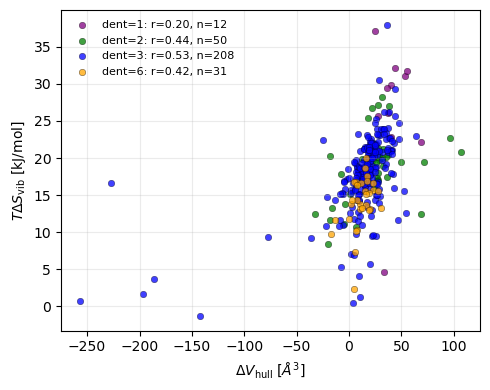

In [10]:
def scatter_by_denticity(feature, target='dHelec'):
    fig, ax = plt.subplots(figsize=(5, 4), tight_layout=True)
    colors = {'1': 'purple', '2': 'green', '3': 'blue', '6': 'orange', 'unknown': 'pink'}

    for denticity in sorted_denticities(rows):
        subset = [row for row in rows if row['denticity'] == denticity]
        pairs = finite_pairs(subset, feature, target)
        if not pairs:
            continue
        x = [pair[0] for pair in pairs]
        y = [pair[1] for pair in pairs]
        r, n = pearson_correlation(subset, feature, target=target)
        label_text = f'dent={denticity}: r={r:.2f}, n={n}' if r is not None else f'dent={denticity}: n={n}'
        ax.scatter(x, y, s=22, alpha=0.75, edgecolor='black', linewidth=0.3, color=colors.get(denticity, 'gray'), label=label_text)

    ax.set_xlabel(feature_labels.get(feature, feature))
    ax.set_ylabel(target_labels.get(target, target))
    ax.legend(frameon=False, fontsize=8)
    ax.grid(alpha=0.25)
    return fig, ax

scatter_by_denticity('dCH', target='TdSvib')
plt.show()


## HS-LS Difference Descriptors

Because several thermodynamic properties are HS-LS differences, this section focuses on paired structural changes: `HS - LS`, absolute changes, and the relative convex-hull volume change. The CShM and convex-hull volume differences are kept explicit because they are the chemically interesting hypotheses here.


In [11]:
difference_features = [
    'dFeN', 'abs_dFeN',
    'dEpsylon', 'abs_dEpsylon',
    'dCShM', 'abs_dCShM',
    'dCH', 'abs_dCH', 'rel_dCH',
    'dFCS_CH', 'abs_dFCS_CH', 'rel_dFCS_CH',
]

all_difference_tables = []
for target in targets:
    for label, subset in group_subsets:
        all_difference_tables.extend(correlation_table(subset, label, target=target, feature_list=difference_features)[:9])

print_table(all_difference_tables)


target   group          feature               r     n
---------------------------------------------------------
dHelec   overall        rel_dCH           0.343   604
dHelec   overall        dCH               0.288   604
dHelec   overall        rel_dFCS_CH       0.087   604
dHelec   overall        abs_dCH           0.072   604
dHelec   overall        dEpsylon         -0.058   604
dHelec   overall        abs_dEpsylon     -0.051   604
dHelec   overall        dFeN             -0.010   604
dHelec   overall        abs_dFeN         -0.010   604
dHelec   overall        dFCS_CH           0.008   604
dHelec   homoleptic     rel_dFCS_CH       0.382   301
dHelec   homoleptic     dFeN              0.287   301
dHelec   homoleptic     abs_dFeN          0.287   301
dHelec   homoleptic     dFCS_CH           0.253   301
dHelec   homoleptic     abs_dFCS_CH       0.253   301
dHelec   homoleptic     dCH               0.184   301
dHelec   homoleptic     rel_dCH           0.142   301
dHelec   homoleptic     

In [12]:
difference_by_denticity = []
for target in targets:
    for denticity in sorted_denticities(rows):
        subset = [row for row in rows if row['denticity'] == denticity]
        difference_by_denticity.extend(correlation_table(subset, f'dent={denticity}', target=target, feature_list=difference_features)[:5])

print_table(difference_by_denticity)


target   group          feature               r     n
---------------------------------------------------------
dHelec   dent=1         dEpsylon         -0.858    12
dHelec   dent=1         abs_dEpsylon      0.841    12
dHelec   dent=1         dCShM            -0.819    12
dHelec   dent=1         abs_dCShM         0.696    12
dHelec   dent=1         rel_dCH          -0.552    12
dHelec   dent=2         abs_dCH           0.369    50
dHelec   dent=2         dCH               0.348    50
dHelec   dent=2         rel_dFCS_CH       0.224    50
dHelec   dent=2         dFeN              0.164    50
dHelec   dent=2         abs_dFeN          0.164    50
dHelec   dent=3         rel_dFCS_CH       0.347   208
dHelec   dent=3         dFeN              0.223   208
dHelec   dent=3         abs_dFeN          0.223   208
dHelec   dent=3         dFCS_CH           0.223   208
dHelec   dent=3         abs_dFCS_CH       0.223   208
dHelec   dent=6         dFeN              0.648    31
dHelec   dent=6         

## Focus On CShM And Convex-Hull Volume Differences

The global Pearson correlations should be treated as exploratory descriptors, not as predictive models. These plots focus on HS-LS differences that have direct structural meaning: changes in CShM and changes in convex-hull molecular volume. The latter is especially relevant because the volume descriptor was added after the original version of this notebook.


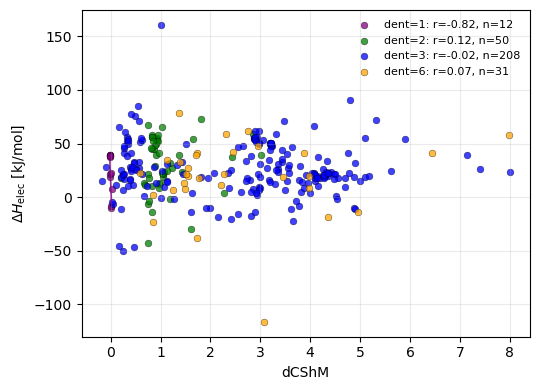

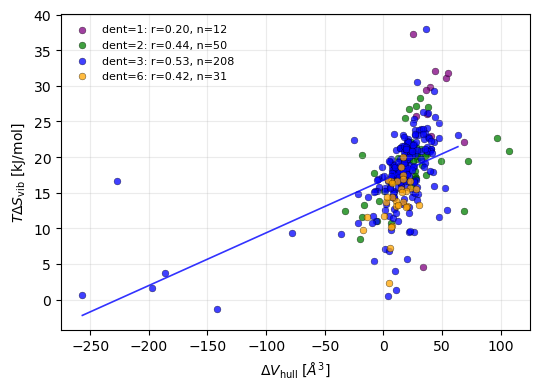

In [13]:
def fit_line(x, y):
    x = np.array(x)
    y = np.array(y)
    m, b = np.polyfit(x, y, 1)
    x_fit = np.linspace(x.min(), x.max(), 200)
    y_fit = m * x_fit + b
    y_pred = m * x + b
    r2 = 1 - np.sum((y - y_pred) ** 2) / np.sum((y - np.mean(y)) ** 2)
    return x_fit, y_fit, r2


def scatter_feature_by_denticity(feature, target='dHelec', min_points_for_fit=6):
    fig, ax = plt.subplots(figsize=(5.5, 4), tight_layout=True)
    colors = {'1': 'purple', '2': 'green', '3': 'blue', '6': 'orange', 'unknown': 'pink'}

    for denticity in sorted_denticities(rows):
        subset = [row for row in rows if row['denticity'] == denticity]
        pairs = finite_pairs(subset, feature, target)
        if not pairs:
            continue
        x = [pair[0] for pair in pairs]
        y = [pair[1] for pair in pairs]
        r, n = pearson_correlation(subset, feature, target=target)
        label_text = f'dent={denticity}: r={r:.2f}, n={n}' if r is not None else f'dent={denticity}: n={n}'
        ax.scatter(x, y, s=24, alpha=0.75, edgecolor='black', linewidth=0.3, color=colors.get(denticity, 'gray'), label=label_text)
        if r is not None and n >= min_points_for_fit and abs(r) > 0.5:
            x_fit, y_fit, r2 = fit_line(x, y)
            ax.plot(x_fit, y_fit, color=colors.get(denticity, 'gray'), linewidth=1.2, alpha=0.8)

    ax.set_xlabel(feature_labels.get(feature, feature))
    ax.set_ylabel(target_labels.get(target, target))
    ax.legend(frameon=False, fontsize=8)
    ax.grid(alpha=0.25)
    return fig, ax

scatter_feature_by_denticity('dCShM', target='dHelec')
plt.show()
scatter_feature_by_denticity('dCH', target='TdSvib')
plt.show()


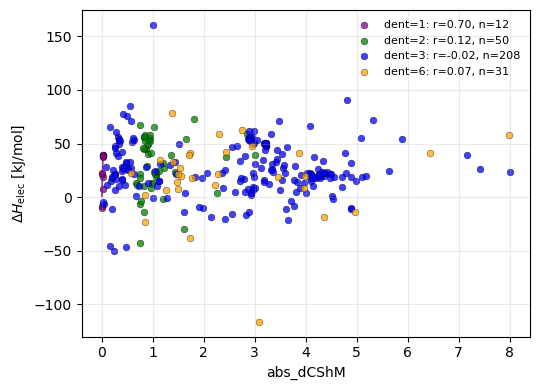

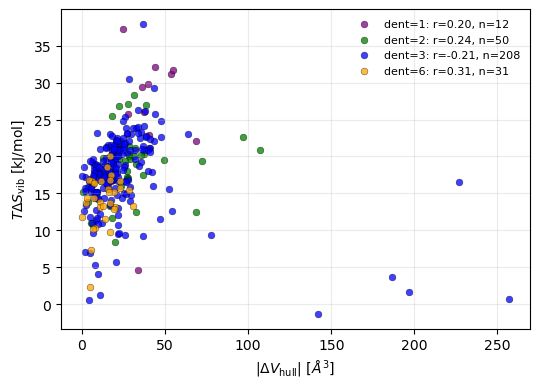

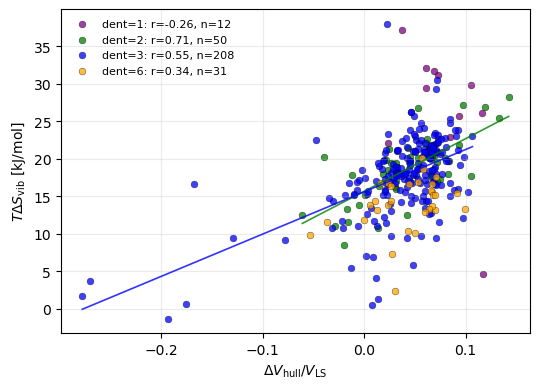

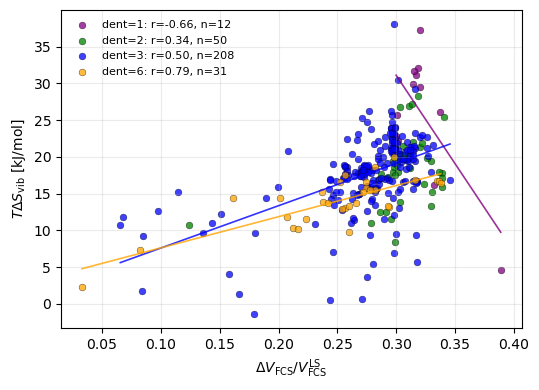

In [14]:
for feature, target in [('abs_dCShM', 'dHelec'), ('abs_dCH', 'TdSvib'), ('rel_dCH', 'TdSvib'), ('rel_dFCS_CH', 'TdSvib')]:
    scatter_feature_by_denticity(feature, target=target)
    plt.show()


In [15]:
for feature in ['dCShM', 'abs_dCShM', 'dCH', 'abs_dCH', 'rel_dCH', 'dFCS_CH', 'abs_dFCS_CH', 'rel_dFCS_CH']:
    print()
    print(feature)
    feature_table = []
    for target in targets:
        for label, subset in group_subsets:
            r, n = pearson_correlation(subset, feature, target=target)
            if r is not None:
                feature_table.append({'group': label, 'target': target, 'feature': feature, 'r': r, 'abs_r': abs(r), 'n': n})
        for denticity in sorted_denticities(rows):
            subset = [row for row in rows if row['denticity'] == denticity]
            r, n = pearson_correlation(subset, feature, target=target)
            if r is not None:
                feature_table.append({'group': f'dent={denticity}', 'target': target, 'feature': feature, 'r': r, 'abs_r': abs(r), 'n': n})
    print_table(feature_table)



dCShM
target   group          feature               r     n
---------------------------------------------------------
dHelec   overall        dCShM            -0.003   604
dHelec   homoleptic     dCShM            -0.016   301
dHelec   heteroleptic   dCShM            -0.220   303
dHelec   dent=1         dCShM            -0.819    12
dHelec   dent=2         dCShM             0.119    50
dHelec   dent=3         dCShM            -0.021   208
dHelec   dent=6         dCShM             0.068    31
dHvib    overall        dCShM             0.433   604
dHvib    homoleptic     dCShM             0.418   301
dHvib    heteroleptic   dCShM             0.368   303
dHvib    dent=1         dCShM             0.442    12
dHvib    dent=2         dCShM             0.122    50
dHvib    dent=3         dCShM             0.518   208
dHvib    dent=6         dCShM             0.053    31
TdSvib   overall        dCShM            -0.083   604
TdSvib   homoleptic     dCShM            -0.222   301
TdSvib   heterole

## Export Correlation Tables

In [16]:
correlation_rows = []
for section, table in [
    ('all_descriptors_grouped', summary_tables),
    ('all_descriptors_by_denticity', by_denticity),
    ('difference_descriptors_grouped', all_difference_tables),
    ('difference_descriptors_by_denticity', difference_by_denticity),
]:
    for row in table:
        correlation_rows.append({
            'Analysis Section': section,
            'Complex Subset': row['group'],
            'thermodynamic term': row['target'],
            'structural parameter': row['feature'],
            'Pearson Correlation': f"{row['r']:.2f}",
            'Num Entries': row['n'],
        })

output_path = outputs_path / 'structure_thermo_correlations.csv'
with open(output_path, 'w', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=['Analysis Section', 'Complex Subset', 'thermodynamic term', 'structural parameter', 'Pearson Correlation', 'Num Entries'])
    writer.writeheader()
    writer.writerows(correlation_rows)

print(output_path)


/Users/sergivela/Documents/SCOPE/Database_SCO/Analysis/1-Analyse_Database/Outputs/structure_thermo_correlations.csv


## Manuscript Figure: Discussed Structure--Thermodynamic Correlations

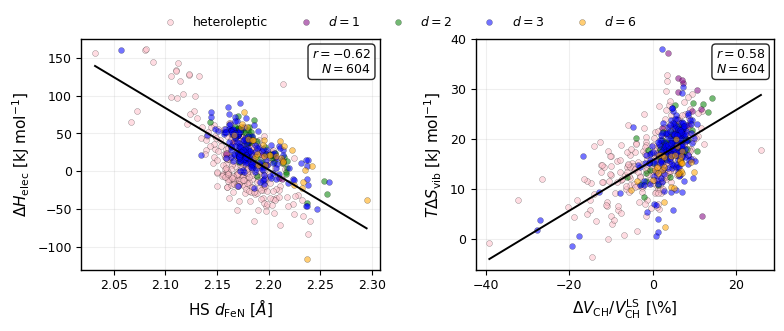

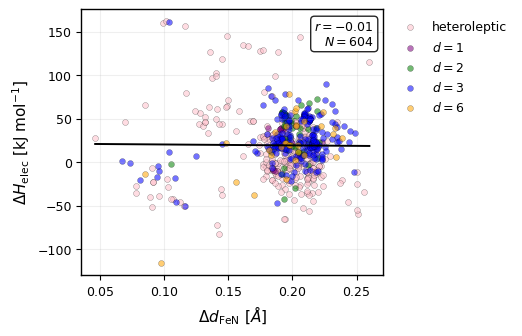

In [17]:
# Strong correlations for the main text; weaker Fe-N difference correlation for the ESI.
main_panel_specs = [
    ('HS_FeN', 'dHelec', 1.0, r'HS $d_{\mathrm{FeN}}$ [$\AA$]', r'$\Delta H_{\mathrm{elec}}$ [kJ mol$^{-1}$]'),
    ('rel_dCH', 'TdSvib', 100.0, r'$\Delta V_{\mathrm{CH}}/V_{\mathrm{CH}}^{\mathrm{LS}}$ [\%]', r'$T\Delta S_{\mathrm{vib}}$ [kJ mol$^{-1}$]'),
]
esi_panel_spec = ('dFeN', 'dHelec', 1.0, r'$\Delta d_{\mathrm{FeN}}$ [$\AA$]', r'$\Delta H_{\mathrm{elec}}$ [kJ mol$^{-1}$]')

plot_groups = [
    ('heteroleptic', [row for row in rows if not row['homoleptic']], 'pink'),
    ('$d=1$', [row for row in rows if row['homoleptic'] and row['denticity'] == '1'], 'purple'),
    ('$d=2$', [row for row in rows if row['homoleptic'] and row['denticity'] == '2'], 'green'),
    ('$d=3$', [row for row in rows if row['homoleptic'] and row['denticity'] == '3'], 'blue'),
    ('$d=6$', [row for row in rows if row['homoleptic'] and row['denticity'] == '6'], 'orange'),
]

def draw_correlation_panel(ax, spec):
    feature, target, x_scale, xlabel, ylabel = spec

    for group_label, subset, color in plot_groups:
        pairs = finite_pairs(subset, feature, target)
        if not pairs:
            continue
        x = x_scale * np.array([pair[0] for pair in pairs])
        y = np.array([pair[1] for pair in pairs])
        ax.scatter(
            x, y, s=18, alpha=0.55, color=color, edgecolor='black',
            linewidth=0.25, label=group_label,
        )

    all_pairs = finite_pairs(rows, feature, target)
    x_all = x_scale * np.array([pair[0] for pair in all_pairs])
    y_all = np.array([pair[1] for pair in all_pairs])
    x_fit, y_fit, _ = fit_line(x_all, y_all)
    ax.plot(x_fit, y_fit, color='black', linewidth=1.4, zorder=5)

    r, n = pearson_correlation(rows, feature, target=target)
    ax.text(
        0.97, 0.96, f'$r={r:.2f}$\n$N={n}$', transform=ax.transAxes,
        ha='right', va='top', fontsize=9,
        bbox=dict(boxstyle='round', facecolor='white', edgecolor='black', alpha=0.85),
    )
    ax.set_xlabel(xlabel, fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.tick_params(axis='both', direction='out', labelsize=9)
    ax.grid(alpha=0.20)
    for spine in ax.spines.values():
        spine.set_color('black')
        spine.set_linewidth(1.0)
    return ax.get_legend_handles_labels()


fig, axs = plt.subplots(1, 2, figsize=(7.7, 3.5))
fig.patch.set_facecolor('white')
for ax, spec in zip(axs, main_panel_specs):
    draw_correlation_panel(ax, spec)

handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.96), ncol=5, frameon=False, fontsize=9)
fig.subplots_adjust(left=0.09, right=0.99, bottom=0.20, top=0.86, wspace=0.32)
figures_path.mkdir(exist_ok=True)
plt.savefig(figures_path / 'structure_thermodynamic_correlations_discussed.png', dpi=400, bbox_inches='tight', facecolor='white')
plt.show()

fig, ax = plt.subplots(figsize=(5.2, 3.5))
fig.patch.set_facecolor('white')
handles, labels = draw_correlation_panel(ax, esi_panel_spec)
ax.legend(handles, labels, loc='upper left', bbox_to_anchor=(1.01, 1.0), frameon=False, fontsize=9)
fig.subplots_adjust(left=0.14, right=0.72, bottom=0.20, top=0.96)
plt.savefig(figures_path / 'structure_thermodynamic_correlation_dFeN_ESI.png', dpi=400, bbox_inches='tight', facecolor='white')
plt.show()

**Main-text caption.** Principal structure--thermodynamic relationships identified in the dataset. Left: electronic HS--LS enthalpy difference as a function of the average HS Fe--N distance. Right: vibrational entropic contribution at 298 K as a function of the relative convex-hull molecular-volume change. **ESI caption.** Electronic HS--LS enthalpy difference as a function of the HS--LS change in average Fe--N distance. In both figures, points are classified by denticity for homoleptic complexes, while heteroleptic complexes are shown separately. Black lines are least-squares fits over the complete dataset; insets report the corresponding Pearson correlation coefficient and number of systems.

## Family-Resolved Structural Fingerprints

This analysis uses only the systems assigned to the eight main $\Delta H_{\mathrm{elec}}$ distributions in notebook 5. Consequently, the structural fingerprints refer to exactly the same 119 systems used to define the family electronic baselines and widths.


In [18]:
family_membership_path = outputs_path / 'ligand_family_dHelec_membership.csv'
family_statistics_path = outputs_path / 'ligand_family_dHelec_statistics.csv'

family_membership_df = pd.read_csv(family_membership_path)
family_statistics_df = pd.read_csv(family_statistics_path)
main_membership_df = family_membership_df[family_membership_df['Main Distribution']].copy()
main_membership_df = main_membership_df.rename(columns={'Refcode': 'id'})

structure_df = pd.DataFrame(rows)[
    ['id', 'HS_FeN', 'HS_Epsylon', 'LS_FeN', 'LS_Epsylon']
]
family_structural_df = main_membership_df.merge(structure_df, on='id', how='inner', validate='one_to_one')
family_structural_df['Family Label'] = family_structural_df.apply(
    lambda row: f"d={int(row['Denticity'])}, {row['Family']}", axis=1
)

assert len(family_structural_df) == len(main_membership_df), 'Missing structural data for accepted family members'

family_structural_statistics = []
for (denticity, family), family_df in family_structural_df.groupby(['Denticity', 'Family'], sort=False):
    electronic_stats = family_statistics_df[
        (family_statistics_df['Denticity'] == denticity)
        & (family_statistics_df['Family'] == family)
    ].iloc[0]
    record = {
        'Denticity': int(denticity),
        'Family': family,
        'Num Main-Distribution Entries': len(family_df),
        'dHelec Base [kJ/mol]': electronic_stats['dHelec Base [kJ/mol]'],
        'dHelec Width [kJ/mol]': electronic_stats['dHelec Width [kJ/mol]'],
    }
    for state in ['HS', 'LS']:
        for parameter, label, unit in [('FeN', 'dFeN', 'Angstrom'), ('Epsylon', 'Sigma', 'deg')]:
            values = family_df[f'{state}_{parameter}']
            record[f'{state} {label} Median [{unit}]'] = values.median()
            record[f'{state} {label} IQR [{unit}]'] = values.quantile(0.75) - values.quantile(0.25)
    family_structural_statistics.append(record)

family_structural_statistics_df = pd.DataFrame(family_structural_statistics)
family_structural_statistics_path = outputs_path / 'ligand_family_structural_statistics.csv'
family_structural_statistics_df.round(3).to_csv(family_structural_statistics_path, index=False)

print(f'Main-distribution systems with structural data: {len(family_structural_df)}')
print(f'Family structural statistics saved to: {family_structural_statistics_path}')
family_structural_statistics_df.round(3)


Main-distribution systems with structural data: 119
Family structural statistics saved to: /Users/sergivela/Documents/SCOPE/Database_SCO/Analysis/1-Analyse_Database/Outputs/ligand_family_structural_statistics.csv


,Denticity,Family,Num Main-Distribution Entries,dHelec Base [kJ/mol],dHelec Width [kJ/mol],HS dFeN Median [Angstrom],HS dFeN IQR [Angstrom],HS Sigma Median [deg],HS Sigma IQR [deg],LS dFeN Median [Angstrom],LS dFeN IQR [Angstrom],LS Sigma Median [deg],LS Sigma IQR [deg]
0,2,"F(3,1)",7,55.37,5.51,2.172,0.003,84.163,1.835,1.978,0.001,59.230,0.485
1,2,"F(4,1)",11,21.19,27.04,2.204,0.008,83.843,11.434,1.996,0.013,52.996,7.064
2,3,"F(1,5)",8,6.75,12.73,2.189,0.008,143.810,1.768,1.972,0.006,89.113,2.804
3,3,"F(4,7)",22,51.22,17.57,2.167,0.006,138.305,7.169,1.956,0.002,76.736,0.720
4,3,"F(5,2)",34,20.27,13.07,2.171,0.001,152.693,1.471,1.955,0.002,86.532,1.635
5,3,"F(6,3)",6,68.36,31.42,2.173,0.020,57.214,21.735,1.992,0.009,14.930,12.611
6,3,"F(6,5)",24,29.47,44.77,2.170,0.018,59.348,25.441,1.975,0.024,19.646,24.594
7,6,"F(3,3)",7,27.58,39.38,2.215,0.018,113.315,19.469,1.984,0.034,71.063,11.520


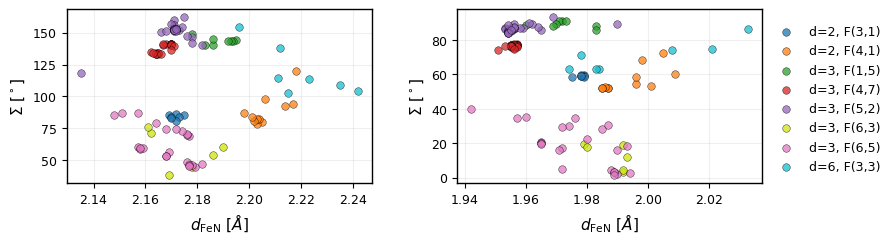

In [26]:
family_order = list(family_structural_df['Family Label'].drop_duplicates())
family_colors = dict(zip(family_order, [
    '#1f77b4', '#ff7f0e', '#2ca02c', '#d62728',
    '#9467bd', "#cfe40d", '#e377c2', '#17becf',
]))

fig, axs = plt.subplots(1, 2, figsize=(9.4, 3.0))
panel_specs = [
    ('HS_FeN', 'HS_Epsylon'),
    ('LS_FeN', 'LS_Epsylon'),
]

for ax, (x_parameter, y_parameter) in zip(axs, panel_specs):
    for family in family_order:
        family_df = family_structural_df[family_structural_df['Family Label'] == family]
        color = family_colors[family]
        ax.scatter(
            family_df[x_parameter], family_df[y_parameter],
            s=30, color=color, edgecolor='black', linewidth=0.35, alpha=0.75,
            label=family if ax is axs[0] else None,
        )
    ax.set_xlabel(r'$d_{\mathrm{FeN}}$ [$\AA$]', fontsize=11)
    ax.set_ylabel(r'$\Sigma$ [$^\circ$]', fontsize=11)
    ax.tick_params(axis='both', direction='out', labelsize=9)
    ax.grid(alpha=0.20)
    for spine in ax.spines.values():
        spine.set_color('black')
        spine.set_linewidth(1.0)

handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='center left', bbox_to_anchor=(0.82, 0.5), frameon=False, fontsize=9)
fig.subplots_adjust(left=0.08, right=0.82, bottom=0.22, top=0.80, wspace=0.28)

family_structural_figure = figures_path / 'ligand_family_structural_fingerprints'
plt.savefig(family_structural_figure.with_suffix('.png'), dpi=400, bbox_inches='tight', facecolor='white')
plt.savefig(family_structural_figure.with_suffix('.pdf'), bbox_inches='tight', facecolor='white')
plt.show()


**Caption.** Family-resolved structural spaces of the HS and LS minima for the 119 systems assigned to the eight main $\Delta H_{\mathrm{elec}}$ distributions. Colors identify ligand families across both panels, and individual systems are shown as circles. Only systems used to define $\Delta H_{\mathrm{elec}}^{base}$ and $\Delta H_{\mathrm{elec}}^{width}$ are included.
